# 历史股票池修复

## tl;dr
本轮只验证数据，不改策略。106只退市股重叠数值一致、52只日期完整一致；量价输入有跨源差异，历史接口返回停牌记录不能当成可成交报价。

## Context & Methods

### Key Assumptions
2018—2026.09；239只交易所代码级快照不是完整历史证券ID主表。原实验哈希不变。价格容差rtol/atol均1e-5；量额rtol1e-6、atol1；固定20只代码排序的交集对照，不是随机全市场。复权重用原算法，非独立公告时点验证。缺失值不补零，API返回成功与可成交资料分开。

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
out = Path.cwd()
recon = json.loads((out/'reconciliation.json').read_text(encoding='utf-8'))
quality = json.loads((out/'source_quality.json').read_text(encoding='utf-8'))
rows = json.loads((out/'inline_chart.json').read_text(encoding='utf-8'))['rows']
plt.rcParams.update({'font.family':'Microsoft YaHei','axes.unicode_minus':False,'font.size':11})

## Data & Results

数据出处：交易所冻结名单；旧TDX缓存、C:/new_tdx原始价/公司行动文件；同花顺只读原始库及冻结面板；BaoStock两个代码原返回。文件哈希和完整SQL单独保留。

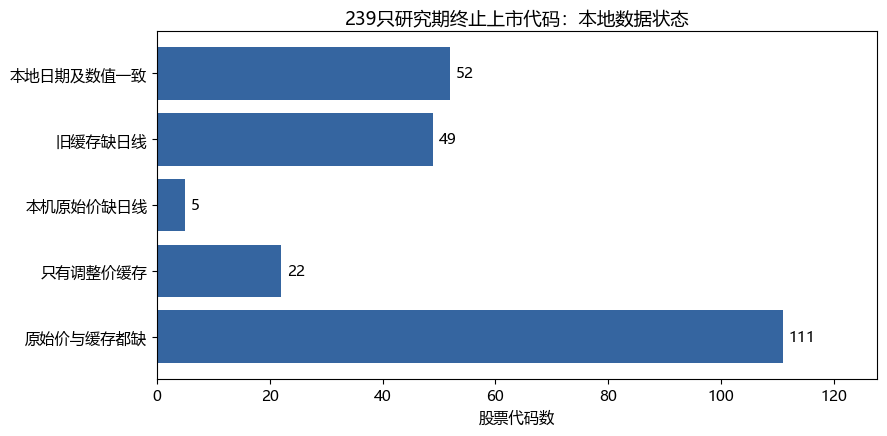

,status,codes
0,本地日期及数值一致,52
1,旧缓存缺日线,49
2,本机原始价缺日线,5
3,只有调整价缓存,22
4,原始价与缓存都缺,111


In [2]:
frame = pd.DataFrame(rows)
assert frame.codes.sum() == 239
fig, ax = plt.subplots(figsize=(9,4.5))
ax.barh(frame.status, frame.codes, color='#3565a0')
ax.invert_yaxis()
ax.set_xlabel('股票代码数')
ax.set_title('239只研究期终止上市代码：本地数据状态')
for i, value in enumerate(frame.codes): ax.text(value+1, i, str(value), va='center')
ax.set_xlim(0,frame.codes.max()*1.15)
fig.tight_layout()
fig.savefig(out/'history-coverage.png',dpi=130)
plt.show()
display(frame)

In [3]:
display(pd.DataFrame(quality['baostock_probes'])[['ts_code','returned_rows','tradestatus_0_rows','unknown_trade_status_rows','missing_volume_rows','usable_traded_rows']])
large = pd.read_csv(out/'large_liquidity_disagreements.csv')
assert len(large) == quality['large_liquidity_disagreement_cells']
display(large.head(12))
display(pd.DataFrame(recon['groups']).T[['codes','common_rows','numeric_overlap_agrees','date_sets_agree','accepted_for_research']])

,ts_code,returned_rows,tradestatus_0_rows,unknown_trade_status_rows,missing_volume_rows,usable_traded_rows
0,601258.SH,20,20,0,20,0
1,000540.SZ,20,20,0,20,0


,ts_code,trade_date,field,tdx_value,hithink_value,tdx_to_hithink_ratio
0,000001.SZ,2025-11-27,vol,1.011847e+08,10118471.0,10.000000
1,000001.SZ,2025-12-01,vol,1.037323e+08,10373227.0,10.000000
2,000001.SZ,2025-11-27,amount,1.178309e+09,11783089.0,100.000008
3,000001.SZ,2025-12-01,amount,1.205480e+09,12054803.0,100.000002
4,000002.SZ,2025-11-27,vol,3.961433e+08,39614332.0,10.000000
5,000002.SZ,2025-12-01,vol,3.212116e+08,32121162.0,10.000000
6,000002.SZ,2025-11-27,amount,2.181601e+09,21816007.0,100.000003
7,000002.SZ,2025-12-01,amount,1.684909e+09,16849089.0,100.000002
8,000006.SZ,2025-11-27,amount,3.129331e+08,31293308.0,10.000000
9,000006.SZ,2025-12-01,amount,4.448399e+08,44483993.0,10.000000


,codes,common_rows,numeric_overlap_agrees,date_sets_agree,accepted_for_research
active_control,20,41495,20,20,0
terminated,106,171728,106,52,0


## Takeaways
已有证据还不支持赚钱方案。修复数据不是盈利承诺；交叉源量额异常的来源和策略影响未定，停牌占位行不等于成交记录。先关闭数据验收缺口，再对冻结规则做一次有退出条件的复核；若未通过，归档版本，不无限调参。历史通过也只可进入冻结的前瞻模拟，不是直接实盘。